# Poissonův proces – strom s padajícím listím

Listy se ze stromu utrhávají v náhodných okamžicích $T_1 < T_2 < \dots$, které tvoří **Poissonův proces s intenzitou $\lambda$** [listů/s]:

* mezipříchodové doby $T_k - T_{k-1}$ jsou nezávislé, $\sim \mathrm{Exp}(\lambda)$,
* čítací proces $N(t) = \#\{k : T_k \le t\}$ (počet utržených listů do času $t$) má $N(t) \sim \mathrm{Po}(\Lambda(t))$,
* $\Lambda(t) = E\,N(t) = \int_0^t \lambda(s)\,ds$ je kumulativní intenzita; pro konstantní $\lambda$ je $\Lambda(t) = \lambda t$.

Při nekonstantní intenzitě $\lambda(t)$ jde o **nehomogenní** Poissonův proces.

**Obsah notebooku**
1. Simulace a kreslení (stačí spustit)
2. Animace s volbou intenzity (ovládací prvky)
3. Animace s předepsaným průběhem $\lambda(t)$
4. Ověření vlastností: mezipříchodové doby a rozdělení $N(T)$
5. Uložení do GIFu


## 1. Simulace a kreslení

In [7]:
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from matplotlib.patches import Polygon, Ellipse
from matplotlib.path import Path
from IPython.display import HTML, display

plt.rcParams["animation.embed_limit"] = 200   # MB, delší animace v notebooku

DT = 0.05            # krok animace [s] -> 20 snímků/s
T_WINDOW = 30.0      # šířka okna dolního grafu [s]
MAX_GROUND = 500     # max. počet listů ležících na zemi

LEAF_COLORS = np.array([
    [0.83, 0.33, 0.00], [0.90, 0.49, 0.13], [0.95, 0.77, 0.06],
    [0.75, 0.22, 0.17], [0.63, 0.25, 0.00], [0.72, 0.58, 0.04],
])
_v = [(0, -1), (0.55, -0.35), (0.5, 0.35), (0, 1), (-0.5, 0.35), (-0.55, -0.35), (0, -1)]
LEAF = Path(_v, [Path.MOVETO] + [Path.LINETO] * 5 + [Path.CLOSEPOLY])   # tvar listu
CROWN = [(0, 6.0, 3.2, 2.4), (-2.3, 5.0, 2.0, 1.6), (2.3, 5.2, 2.0, 1.6), (0, 7.7, 2.2, 1.5)]


def parse_lam(lam):
    """Číslo -> konstantní λ; text '1@0,6@8' -> po částech konstantní λ(t) (hodnota@čas_od)."""
    if not isinstance(lam, str):
        v = float(lam)
        return lambda t: v
    if "@" not in lam:
        v = float(lam)
        return lambda t: v
    parts = sorted((float(b), float(a)) for a, b in (p.split("@") for p in lam.split(",")))
    starts = np.array([p[0] for p in parts])
    vals = [p[1] for p in parts]
    return lambda t: vals[max(0, np.searchsorted(starts, t, side="right") - 1)]


class Simulation:
    def __init__(self, lam, seed=None):
        self.rng = np.random.default_rng(seed)
        self.crown = self._crown_points(700)
        self.reset(lam)

    def _crown_points(self, n):
        pts = []
        while len(pts) < n:
            x, y = self.rng.uniform(-4.5, 4.5), self.rng.uniform(3.2, 9.4)
            if any(((x - cx) / a) ** 2 + ((y - cy) / b) ** 2 < 1 for cx, cy, a, b in CROWN):
                pts.append((x, y))
        return np.array(pts)

    def reset(self, lam=None):
        if lam is not None:
            self.lam = lam
        self.t = 0.0
        self.t_next = self.rng.exponential(1 / self.lam)
        self.events = []                          # časy utržení T_1, T_2, ...
        self.hist_t, self.hist_L = [0.0], [0.0]   # průběh Λ(t)
        self.Lam = 0.0
        self.falling = {k: np.empty(0) for k in ("x0", "y", "vy", "amp", "freq", "ph", "ts")}
        self.fall_col = np.empty((0, 3))
        self.ground_xy = np.empty((0, 2))
        self.ground_col = np.empty((0, 3))

    def set_lam(self, lam):
        if lam != self.lam:
            self.lam = lam
            # bezpaměťovost Exp: zbývající čekací dobu lze losovat znovu od teď
            self.t_next = self.t + self.rng.exponential(1 / lam)

    def _spawn(self, ts):
        r = self.rng
        x0, y0 = self.crown[r.integers(len(self.crown))]
        vy = r.uniform(1.0, 1.8)
        new = dict(x0=x0, y=y0 - vy * (self.t - ts), vy=vy, amp=r.uniform(0.2, 0.7),
                   freq=r.uniform(1.5, 3.5), ph=r.uniform(0, 2 * np.pi), ts=ts)
        for k in self.falling:
            self.falling[k] = np.append(self.falling[k], new[k])
        self.fall_col = np.vstack([self.fall_col, LEAF_COLORS[r.integers(len(LEAF_COLORS))]])
        self.events.append(ts)

    def step(self):
        self.t += DT
        while self.t_next <= self.t:              # přesné časy událostí, ne po snímcích
            self._spawn(self.t_next)
            self.t_next += self.rng.exponential(1 / self.lam)
        self.Lam += self.lam * DT
        self.hist_t.append(self.t)
        self.hist_L.append(self.Lam)

        f = self.falling
        f["y"] = f["y"] - f["vy"] * DT
        landed = f["y"] <= 0.05
        if landed.any():
            xs = self.x_falling()[landed]
            ys = self.rng.uniform(-0.35, 0.05, landed.sum())
            self.ground_xy = np.vstack([self.ground_xy, np.column_stack([xs, ys])])[-MAX_GROUND:]
            self.ground_col = np.vstack([self.ground_col, self.fall_col[landed]])[-MAX_GROUND:]
            for k in f:
                f[k] = f[k][~landed]
            self.fall_col = self.fall_col[~landed]

    def x_falling(self):
        f = self.falling
        return f["x0"] + f["amp"] * np.sin(f["freq"] * (self.t - f["ts"]) + f["ph"])


def build_figure(sim, dpi=70, bottom=0.07, height=7.6):
    fig = plt.figure(figsize=(7, height), dpi=dpi)
    gs = fig.add_gridspec(2, 1, height_ratios=[3.2, 1.2], hspace=0.12,
                          left=0.1, right=0.97, top=0.97, bottom=bottom)
    ax, axN = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])

    ax.set_xlim(-6, 6); ax.set_ylim(-0.5, 10)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_facecolor("#eaf2f8")
    ax.axhspan(-0.5, 0.05, color="#8d7b4a", zorder=0)
    ax.add_patch(Polygon([(-0.45, 0), (0.45, 0), (0.28, 4.5), (-0.28, 4.5)], color="#5d4037", zorder=1))
    for (x1, y1, x2, y2) in [(0, 3.6, -2.2, 5.0), (0, 4.0, 2.2, 5.2), (0, 4.4, 0, 7.4)]:
        ax.plot([x1, x2], [y1, y2], color="#5d4037", lw=4, zorder=1, solid_capstyle="round")
    for cx, cy, a, b in CROWN:
        ax.add_patch(Ellipse((cx, cy), 2 * a, 2 * b, color="#e9b872", alpha=0.35, zorder=1))
    cols = LEAF_COLORS[sim.rng.integers(len(LEAF_COLORS), size=len(sim.crown))]
    ax.scatter(*sim.crown.T, s=55, marker=LEAF, c=cols, zorder=2, linewidths=0)

    art = dict(
        fall=ax.scatter([], [], s=70, marker=LEAF, zorder=4, linewidths=0.3, edgecolors="#4e342e"),
        ground=ax.scatter([], [], s=55, marker=LEAF, zorder=3, linewidths=0),
        txt=ax.text(-5.8, 9.7, "", va="top", ha="left", fontsize=11, family="monospace",
                    bbox=dict(facecolor="white", alpha=0.8, edgecolor="none")),
    )
    art["N"], = axN.plot([], [], drawstyle="steps-post", color="#c0392b", lw=1.8, label="N(t)")
    art["L"], = axN.plot([], [], "--", color="#34495e", lw=1.2, label=r"$E\,N(t)=\Lambda(t)$")
    axN.set_xlabel("t [s]"); axN.set_ylabel("počet listů")
    axN.legend(loc="upper left", fontsize=9); axN.grid(alpha=0.3)
    art["axN"] = axN
    return fig, art


def make_update(sim, art, lam_fun=None):
    def update(_frame):
        if lam_fun is not None:
            sim.set_lam(lam_fun(sim.t))
        sim.step()
        xy = np.column_stack([sim.x_falling(), sim.falling["y"]])
        art["fall"].set_offsets(xy if len(xy) else np.empty((0, 2)))
        art["fall"].set_facecolor(sim.fall_col if len(sim.fall_col) else "none")
        art["ground"].set_offsets(sim.ground_xy if len(sim.ground_xy) else np.empty((0, 2)))
        art["ground"].set_facecolor(sim.ground_col if len(sim.ground_col) else "none")

        n = len(sim.events)
        art["txt"].set_text(f"t     = {sim.t:6.1f} s\nλ     = {sim.lam:6.2f} /s\n"
                            f"N(t)  = {n:6d}\nΛ(t)  = {sim.Lam:6.1f}")
        art["N"].set_data([0.0] + sim.events + [sim.t], [0] + list(range(1, n + 1)) + [n])
        art["L"].set_data(sim.hist_t, sim.hist_L)
        axN = art["axN"]
        t0 = max(0.0, sim.t - T_WINDOW)
        axN.set_xlim(t0, max(T_WINDOW, sim.t) + 0.5)
        lo = sum(1 for e in sim.events if e < t0)
        axN.set_ylim(min(lo, np.interp(t0, sim.hist_t, sim.hist_L)) - 1, max(n, sim.Lam) * 1.08 + 2)
    return update


def animace(lam=2.0, duration=15, seed=None, dpi=70):
    """Vrátí FuncAnimation. lam = číslo, nebo rozpis '1@0,5@8,0.5@16'."""
    lam_fun = parse_lam(lam)
    sim = Simulation(lam_fun(0.0), seed)
    fig, art = build_figure(sim, dpi=dpi)
    anim = FuncAnimation(fig, make_update(sim, art, lam_fun),
                         frames=int(duration / DT), interval=DT * 1000)
    plt.close(fig)          # aby se nevykreslil i statický obrázek
    anim.sim = sim          # pro pozdější analýzu
    return anim

## 2. Animace s volbou intenzity

Nastavte $\lambda$, délku a případně seed a klikněte na **Spustit simulaci**. Vygenerování trvá několik sekund, poté se zobrazí přehrávač (lze krokovat po snímcích, zpomalit, pustit dozadu).

Pole *rozpis λ(t)* je nepovinné: např. `1@0,5@8,0.5@16` znamená $\lambda=1$ od $t=0$, $\lambda=5$ od $t=8$, $\lambda=0{,}5$ od $t=16$. Pokud je vyplněné, má přednost před posuvníkem.

In [2]:
import ipywidgets as w

lam_w  = w.FloatSlider(value=2.0, min=0.1, max=10, step=0.1, description="λ [1/s]",
                       continuous_update=False, style={"description_width": "90px"})
sched_w = w.Text(value="", placeholder="např. 1@0,5@8,0.5@16", description="rozpis λ(t)",
                 style={"description_width": "90px"})
dur_w  = w.IntSlider(value=15, min=5, max=40, step=1, description="délka [s]",
                     style={"description_width": "90px"})
seed_w = w.IntText(value=0, description="seed (0=náh.)", style={"description_width": "90px"})
btn    = w.Button(description="Spustit simulaci", button_style="success", icon="play")
out    = w.Output()

def _run(_):
    lam = sched_w.value.strip() or lam_w.value
    seed = seed_w.value or None
    with out:
        out.clear_output()
        print("Generuji animaci…")
        anim = animace(lam, dur_w.value, seed)
        html = anim.to_jshtml(default_mode="once")
        out.clear_output(wait=True)
        display(HTML(html))

btn.on_click(_run)
display(w.VBox([w.HBox([lam_w, dur_w]), w.HBox([sched_w, seed_w]), btn, out]))

## 3. Animace s předepsaným průběhem $\lambda(t)$ (bez ovládacích prvků)

Funguje i tam, kde nejsou k dispozici `ipywidgets` (např. export do HTML).

In [8]:
anim = animace(lam="1@0,5@8,0.5@16", duration=24, seed=3)
HTML(anim.to_jshtml(default_mode="once"))

## 4. Ověření vlastností procesu

Bez animace nasimulujeme dlouhou trajektorii a mnoho nezávislých opakování a porovnáme s teorií:

* histogram mezipříchodových dob vs. hustota $\lambda e^{-\lambda x}$,
* rozdělení $N(T)$ přes opakování vs. $\mathrm{Po}(\lambda T)$.

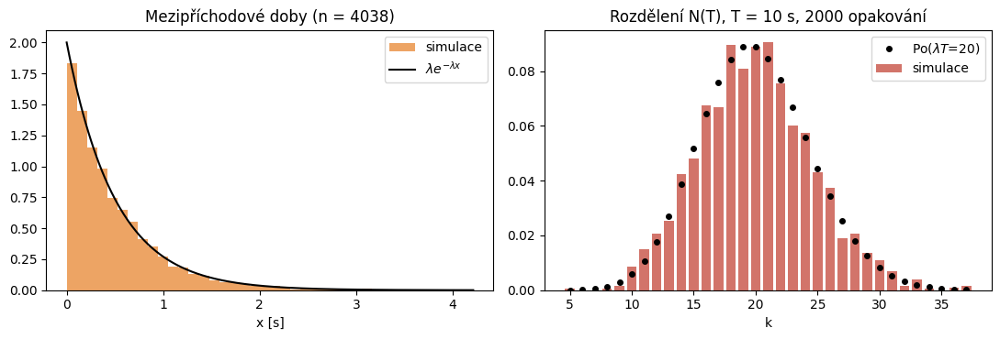

průměr mezer   0.495   (teorie 1/λ = 0.500)
E N(T)         20.00   (teorie λT = 20.00)
var N(T)       21.10   (teorie λT = 20.00)


In [4]:
lam, T, R = 2.0, 10.0, 2000
rng = np.random.default_rng(1)

def poisson_times(lam, T, rng):
    """Časy událostí homogenního Poissonova procesu na [0, T] přes exponenciální mezery."""
    t, out = 0.0, []
    while True:
        t += rng.exponential(1 / lam)
        if t > T:
            return np.array(out)
        out.append(t)

# (a) mezipříchodové doby z jedné dlouhé trajektorie
times = poisson_times(lam, 2000, rng)
gaps = np.diff(np.concatenate([[0.0], times]))

# (b) N(T) z R nezávislých opakování
counts = np.array([len(poisson_times(lam, T, rng)) for _ in range(R)])

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.linspace(0, gaps.max(), 300)
a1.hist(gaps, bins=40, density=True, color="#e67e22", alpha=0.7, label="simulace")
a1.plot(x, lam * np.exp(-lam * x), "k", lw=1.5, label=r"$\lambda e^{-\lambda x}$")
a1.set_title(f"Mezipříchodové doby (n = {len(gaps)})"); a1.set_xlabel("x [s]"); a1.legend()

k = np.arange(counts.min(), counts.max() + 1)
pmf = np.exp(k * np.log(lam * T) - lam * T - np.array([math.lgamma(i + 1) for i in k]))
a2.bar(k, np.bincount(counts, minlength=k.max() + 1)[k] / R, color="#c0392b", alpha=0.7, label="simulace")
a2.plot(k, pmf, "ko", ms=4, label=rf"Po($\lambda T$={lam*T:g})")
a2.set_title(f"Rozdělení N(T), T = {T:g} s, {R} opakování"); a2.set_xlabel("k"); a2.legend()
plt.tight_layout(); plt.show()

print(f"průměr mezer   {gaps.mean():.3f}   (teorie 1/λ = {1/lam:.3f})")
print(f"E N(T)         {counts.mean():.2f}   (teorie λT = {lam*T:.2f})")
print(f"var N(T)       {counts.var(ddof=1):.2f}   (teorie λT = {lam*T:.2f})")

## 5. Uložení do GIFu

In [5]:
anim = animace(lam="1@0,5@8,0.5@16", duration=24, seed=3, dpi=60)
anim.save("poisson_listi.gif", writer=PillowWriter(fps=int(round(1 / DT))))
print("Uloženo: poisson_listi.gif")

Uloženo: poisson_listi.gif
